# Deciding When to Write Memory

Last week, the support agent kept a profile of each customer in the store. A `write_memory` node asked the model to update the profile on every turn, before the assistant answered.

Most messages a customer sends contain nothing worth remembering: "Where is my order?", "Thanks, that's all." For each of them, `write_memory` still calls the model, the customer waits for that call, and the model may add details that do not belong in a profile.

In this notebook, we'll put a decision in front of `write_memory`: **is this message worth remembering?** Only when the answer is yes does the agent update the profile. We'll make this decision with a **decision model**, and we'll compare it with asking the LLM.

Here is the agent we'll build by the end of the notebook.

![The support agent with a memory gate](figures/memory_gate_graph.png)

In [1]:
from dotenv import load_dotenv
import os

load_dotenv()
keys = ["OPENAI_API_KEY", "ANTHROPIC_API_KEY", "GOOGLE_API_KEY", "TYPESAFE_API_KEY"]
print("API keys found:", [k for k in keys if os.getenv(k)] or "none")

API keys found: ['OPENAI_API_KEY', 'ANTHROPIC_API_KEY', 'GOOGLE_API_KEY', 'TYPESAFE_API_KEY']


## 0. Model Setup

Execute one of the following to define the model. The model answers the customer, updates the profile, and plays the LLM in the comparison in section 2.

In [ ]:
from langchain_ollama import ChatOllama

model = ChatOllama(model="qwen3.5:9b", reasoning=False)

In [ ]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="gpt-4.1-mini")

In [2]:
from langchain.chat_models import init_chat_model

model = init_chat_model(model="claude-haiku-5-5")

In [ ]:
from langchain_google_genai import ChatGoogleGenerativeAI

model = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

## 1. Decision models

An LLM reads text and writes text. A **decision model** reads an input and answers questions about it, and each question has a fixed set of possible answers. It does not write any text. Instead, it returns a probability for each answer.

We'll use **Jev**, a decision model made by TypeSafe. We send it two things:

- The **state**: the input to decide about. For us, the customer's message.
- The **questions**: what to decide. Each question has a name, a type, instructions, and criteria that say what each answer means.

Jev has three types of questions:

- `Noul`: a yes-or-no question. Jev returns the probability that the answer is yes.
- `Choice`: pick one of several options, such as which team should handle a ticket.
- `Score`: pick a level on a scale, such as how urgent a message is.

Jev answers all the questions in one call, and one call takes a fraction of a second. We need a single yes-or-no question.

`TypeSafeClient` reads your key from `TYPESAFE_API_KEY` in your `.env`.

In [3]:
from typesafe_sdk import TypeSafeClient, Noul

jev = TypeSafeClient()

Here is our question. The criteria say what *yes* and *no* mean, the same way we would explain the rule to a new support agent. Passwords and account numbers are on the *no* side: a support agent should never keep them in a customer's profile.

In [4]:
REMEMBER = Noul(
    instructions="The customer's message tells us something about the customer that would still be useful "
                 "in a later conversation.",
    criteria={
        "true": "A lasting preference, a lasting fact about the customer, a goal they are working toward, "
                "or a correction to something about them.",
        "false": "A request for this time only, a hypothetical, a fact about someone else, a detail of the "
                 "current task, a question or small talk, or a password, login, or ID, account, or card "
                 "number, which is never saved.",
    },
)

The state holds the customer's message and the agent's turn before it. Some messages only make sense with that turn: "Yes, that's my new address" is worth remembering only because of what the agent asked.

In [5]:
def as_state(agent_turn, customer_message):
    return f"Agent's previous turn: {agent_turn or '(none)'}\n\nCustomer's message: {customer_message}"


def remember_probability(agent_turn, customer_message):
    """Jev's probability that the customer's message is worth remembering."""
    response = jev.system_one(state=as_state(agent_turn, customer_message), questions={"remember": REMEMBER})
    return response.nouls["remember"].noul

Let's try three messages.

In [6]:
messages = [
    "Please always reply to me in Spanish.",
    "Where is my order HT-1001?",
    "My Husky account password is Sunflower88! Can you keep it so I don't have to look it up?",
]
for text in messages:
    print(f"{remember_probability(None, text):.2f}  {text}")

0.95  Please always reply to me in Spanish.
0.13  Where is my order HT-1001?
0.14  My Husky account password is Sunflower88! Can you keep it so I don't have to look it up?


The first message is a lasting preference, and Jev gives it a high probability. The second is a question about one order, and the third is a password, so both get a low probability.

## 2. Jev and the LLM on Husky Tech messages

To see how good these decisions are, we need messages whose right answer we know. `husky_cases.json` has 40 messages to the Husky Tech support agent. In 20 of them, the customer tells us something worth remembering, and in the other 20 they do not. The messages were written and labeled with Claude, and each label was checked by a second, separate labeling.

In [7]:
import json

cases = json.load(open("husky_cases.json"))
print(len(cases), "cases,", sum(c["remember"] for c in cases), "worth remembering")
for c in cases[:3]:
    print(f"\n[{c['type']}] remember: {c['remember']}")
    print("  agent:   ", c["assistant_before"] or "(none)")
    print("  customer:", c["user_message"])

40 cases, 20 worth remembering

[task_detail] remember: False
  agent:    (none)
  customer: Good afternoon. I received two chargers instead of the one I ordered under HT-55120. Should I send the extra one back, and if so, how?

[goal] remember: True
  agent:    Your headphones should arrive within 3-5 business days.
  customer: Good, I'm starting music production lessons in two weeks!

[one_off] remember: False
  agent:    I can walk you through the return process step by step, or send a full summary. What works best?
  customer: for now just give me the short version pls, im on my phone at the bus stop and cant read a wall of text lol


Each case has a `type` that says what kind of message it is, such as `preference`, `one_off` (a request for this time only), or `credential` (a password or an account number). We'll use the types when we read the mistakes.

### The LLM as the judge

The other way to make this decision is to ask the LLM, with structured output, as the reviewer decided in W07b. We give it the same rules as Jev, so that the comparison is fair.

In [8]:
from pydantic import BaseModel, Field
from langchain.messages import SystemMessage, HumanMessage


class MemoryDecision(BaseModel):
    remember: bool = Field(description="True if the message should be saved to the customer's long-term memory.")


LLM_GATE_PROMPT = """You decide whether a customer's message to a support agent should be saved to the customer's
long-term memory.

Save it if the message tells us something about the customer that would still be useful in a later conversation:
a lasting preference, a lasting fact about the customer, a goal they are working toward, or a correction to
something about them.

Do not save it if it is a request for this time only, a hypothetical, a fact about someone else, a detail of the
current task, a question or small talk, or a password, login, or ID, account, or card number, which is never
saved."""

llm_judge = model.with_structured_output(MemoryDecision)


def llm_should_remember(agent_turn, customer_message):
    """The LLM's decision: True or False."""
    request = [SystemMessage(content=LLM_GATE_PROMPT), HumanMessage(content=as_state(agent_turn, customer_message))]
    return llm_judge.invoke(request).remember

Now we run both on every case and time each call. Jev's probability becomes a decision with a threshold: we remember the message when the probability is at least 0.5.

This makes 40 calls to your model. On the Gemini free tier, which allows 15 calls a minute, the loop will slow down and may stop with a 429 error. If it does, wait a minute and run it again.

In [9]:
import time

results = []
for c in cases:
    start = time.time()
    p = remember_probability(c["assistant_before"], c["user_message"])
    jev_seconds = time.time() - start

    start = time.time()
    llm = llm_should_remember(c["assistant_before"], c["user_message"])
    llm_seconds = time.time() - start

    results.append({"case": c, "jev_p": p, "jev": p >= 0.5, "llm": llm,
                    "jev_seconds": jev_seconds, "llm_seconds": llm_seconds})

n = len(results)
print(f"Jev: {sum(r['jev'] == r['case']['remember'] for r in results)} of {n} correct, "
      f"{sum(r['jev_seconds'] for r in results) / n:.2f} s per message")
print(f"LLM: {sum(r['llm'] == r['case']['remember'] for r in results)} of {n} correct, "
      f"{sum(r['llm_seconds'] for r in results) / n:.2f} s per message")

Jev: 38 of 40 correct, 0.07 s per message
LLM: 34 of 40 correct, 0.62 s per message


Here are the cases where at least one of them was wrong.

In [10]:
for r in results:
    c = r["case"]
    if r["jev"] != c["remember"] or r["llm"] != c["remember"]:
        print(f"case {c['case']} [{c['type']}] right answer: {c['remember']} | "
              f"Jev: {r['jev_p']:.2f} | LLM: {r['llm']}")
        print("   ", c["user_message"][:200], "\n")

case 2 [goal] right answer: True | Jev: 0.83 | LLM: False
    Good, I'm starting music production lessons in two weeks! 

case 4 [fact] right answer: True | Jev: 0.84 | LLM: False
    Its for my 2021 M1 MacBook Pro, I also have an iPad Air so ideally something that works with both of them tbh 

case 6 [fact] right answer: True | Jev: 0.59 | LLM: False
    Samsung QLED 65 inch, Q80B I think 

case 11 [question] right answer: False | Jev: 0.69 | LLM: False
    No worries at all, these things happen. Honestly the chat's been way faster than calling, so no complaints from me. What's the next step? 

case 13 [goal_sensitive] right answer: True | Jev: 0.83 | LLM: False
    hey can i cancel the gaming headset order? im trying to pay off my credit card debt by summer and honestly dont need it rn 

case 14 [fact] right answer: True | Jev: 0.78 | LLM: False
    hi there, i bought the smartwatch from you guys and i cant get it to pair. tried like 10 times. my phone is a samsung galaxy s23 and my 

In our runs with Claude Haiku, Jev was right on 38 of the 40 cases and took about 0.07 seconds per message. The LLM was right on 34 or 35 and took about 0.6 seconds. Most of the LLM's mistakes were lasting facts that the customer mentioned in passing, such as the laptop they own, which it decided not to save. Your numbers will differ with your model, so read your own mistakes.

Jev is also cheap: TypeSafe charges $0.042 per million input tokens, and one of these decisions is about 400 tokens.

### The threshold

Jev gives us a probability, and we chose where to draw the line. A lower threshold misses fewer memories, but it sends more messages to `write_memory`. A higher threshold saves more calls and misses more. The LLM's answer is only yes or no, so it has no threshold to adjust.

In [11]:
for threshold in [0.3, 0.5, 0.7]:
    saved = [r for r in results if r["jev_p"] >= threshold]
    missed = sum(1 for r in results if r["case"]["remember"] and r["jev_p"] < threshold)
    wrongly_saved = sum(1 for r in saved if not r["case"]["remember"])
    print(f"threshold {threshold}: {len(saved)} messages saved, {missed} memories missed, "
          f"{wrongly_saved} saved that should not be")

threshold 0.3: 30 messages saved, 0 memories missed, 10 saved that should not be
threshold 0.5: 22 messages saved, 0 memories missed, 2 saved that should not be
threshold 0.7: 19 messages saved, 1 memories missed, 0 saved that should not be


### How many memory writes the gate saves

Without a gate, `write_memory` runs on every message: 40 model calls for these 40 cases. With a gate, it runs only on the messages the gate lets through. A good gate removes many writes and misses few memories.

In [12]:
total = len(results)
needed = sum(r["case"]["remember"] for r in results)
print(f"No gate:  {total} writes, 0 of {needed} memories missed")

for name, decisions in [("Jev gate", [r["jev"] for r in results]), ("LLM gate", [r["llm"] for r in results])]:
    writes = sum(decisions)
    missed = sum(1 for r, d in zip(results, decisions) if r["case"]["remember"] and not d)
    print(f"{name}: {writes} writes ({1 - writes / total:.0%} fewer), {missed} of {needed} memories missed")

No gate:  40 writes, 0 of 20 memories missed
Jev gate: 22 writes (45% fewer), 0 of 20 memories missed
LLM gate: 14 writes (65% fewer), 6 of 20 memories missed


Read the two numbers together. A gate that says no more often removes more writes, but it also misses more memories, and a missed memory is the costlier mistake: the customer has to tell us again. In our runs with Claude Haiku, the Jev gate removed 45% of the writes and missed none of the 20 memories. The LLM gate removed more writes, 60 to 65%, because it missed 5 or 6 of the memories.

Two more things to keep in mind:

- Half of these 40 messages are worth remembering, by design, so no gate can remove more than half the writes here. In a real conversation, far fewer messages are worth remembering. In section 3, it is one message out of five.
- The LLM gate makes a model call of its own on every message, so it removes writes but not model calls. Jev's call costs a small fraction of a model call and a fraction of the time.

## 3. The gate in the support agent

Now let's put the decision into the agent from W11b.1. The graph is the same, except for where it starts: instead of always going to `write_memory`, it asks Jev first. This is the graph from the top of the notebook.

![The support agent with a memory gate](figures/memory_gate_graph.png)

The decision is a routing function on a conditional edge, the way `tools_condition` decides after the assistant whether to call a tool. We do not need a new node.

Here are the prompts and the two nodes from W11b.1, unchanged except for one line: `write_memory` adds the thread to `memory_calls` each time it runs, so we can count its model calls.

In [13]:
from langchain_core.runnables import RunnableConfig
from langgraph.graph import StateGraph, MessagesState, START
from langgraph.prebuilt import ToolNode, tools_condition
from langgraph.checkpoint.memory import InMemorySaver
from langgraph.store.base import BaseStore
from langgraph.store.memory import InMemoryStore

import support_tools as st

ASSISTANT_PROMPT = st.SYSTEM_PROMPT + """

Here is what we know about this customer from earlier conversations (it may be empty).
Follow any preferences it lists.
{memory}"""

WRITE_MEMORY_PROMPT = """You keep a short profile of a Husky Tech customer, to personalize future conversations.

CURRENT PROFILE:
{memory}

Read the customer's messages below and update the profile with anything new the customer has told us about
themselves, such as preferences, the devices they own, or problems they have had.
- Write the profile as a short bulleted list.
- If something new conflicts with the current profile, keep the newer version.
- Include only what the customer said. Do not guess.

Return only the updated profile."""

model_with_tools = model.bind_tools(st.TOOLS)
memory_calls = []


def get_profile(config, store):
    """The customer's profile from the store, or a note that there is none."""
    customer_id = config["configurable"]["customer_id"]
    item = store.get(("customers", customer_id), "profile")
    return item.value["memory"] if item else "No profile yet."


def write_memory(state: MessagesState, config: RunnableConfig, store: BaseStore) -> dict:
    """Update the customer's profile from the conversation, and save it."""
    memory_calls.append(config["configurable"]["thread_id"])
    memory_prompt = WRITE_MEMORY_PROMPT.format(memory=get_profile(config, store))
    customer_messages = [m for m in state["messages"] if m.type == "human"]
    profile = model.invoke([SystemMessage(content=memory_prompt)] + customer_messages)
    customer_id = config["configurable"]["customer_id"]
    store.put(("customers", customer_id), "profile", {"memory": profile.text})
    return {}


def assistant(state: MessagesState, config: RunnableConfig, store: BaseStore) -> dict:
    """ReAct assistant, with the customer's profile in the system prompt."""
    sys_msg = SystemMessage(content=ASSISTANT_PROMPT.format(memory=get_profile(config, store)))
    return {"messages": [model_with_tools.invoke([sys_msg] + state["messages"])]}

Next, the routing function. The newest message in the state is the customer's. The agent's previous turn is the last message from the agent that has text, because the agent's tool calls have none.

In [14]:
THRESHOLD = 0.5


def worth_remembering(state: MessagesState) -> str:
    """Ask Jev whether the customer's newest message is worth remembering, and route on the answer."""
    customer_message = state["messages"][-1].text
    agent_turns = [m.text for m in state["messages"][:-1] if m.type == "ai" and m.text]
    agent_turn = agent_turns[-1] if agent_turns else None

    p = remember_probability(agent_turn, customer_message)
    print(f"           Jev: remember = {p:.2f}")
    return "write_memory" if p >= THRESHOLD else "assistant"

`build_memory_support` is the helper from W11b.1 with one new argument. With `gated=False`, the graph always starts at `write_memory`, as in W11b.1. With `gated=True`, it starts with `worth_remembering`.

In [15]:
def build_memory_support(store, gated):
    builder = StateGraph(MessagesState)
    builder.add_node("write_memory", write_memory)
    builder.add_node("assistant", assistant)
    builder.add_node("tools", ToolNode(st.TOOLS))
    if gated:
        builder.add_conditional_edges(START, worth_remembering, ["write_memory", "assistant"])
    else:
        builder.add_edge(START, "write_memory")
    builder.add_edge("write_memory", "assistant")
    builder.add_conditional_edges("assistant", tools_condition)
    builder.add_edge("tools", "assistant")
    return builder.compile(checkpointer=InMemorySaver(), store=store)

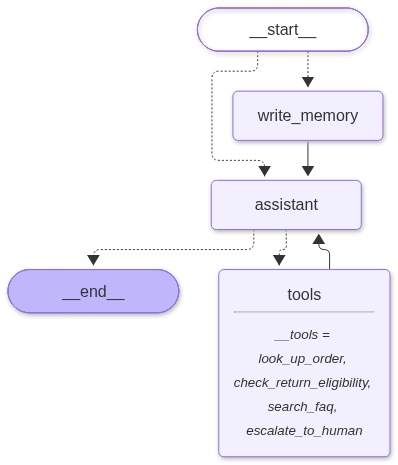

In [16]:
from IPython.display import Image, display

display(Image(build_memory_support(InMemoryStore(), gated=True).get_graph().draw_mermaid_png()))

`chat` is the function from W11b.1. It prints the customer's message and the agent's reply.

In [17]:
def chat(agent, text, thread, customer_id):
    """One turn on a thread. Prints the customer's message and the agent's reply."""
    config = {"configurable": {"thread_id": thread, "customer_id": customer_id}}
    print(f"[{thread}] customer: {text}")
    out = agent.invoke({"messages": [HumanMessage(content=text)]}, config)
    print(f"[{thread}] agent:    {out['messages'][-1].text}\n")
    return out

Here is one week with C-17. On Monday, C-17 asks for Spanish, checks an order, offers a password, and says goodbye. On Friday, C-17 comes back on a new thread. Only the first message is worth remembering.

In [18]:
monday = [
    "Hi, I'm customer C-17. Please always reply to me in Spanish.",
    "Where is my order HT-1001?",
    "My Husky account password is Sunflower88! Can you keep it so I don't have to look it up?",
    "Thanks, that's all for today.",
]
friday = "Hi, what are your support hours?"
week = {}       # the number of write_memory calls and the seconds, for each agent

### Without the gate

First, the agent from last week, which updates the profile on every turn.

In [19]:
memory_calls.clear()
store = InMemoryStore()
support = build_memory_support(store, gated=False)

start = time.time()
for text in monday:
    _ = chat(support, text, "monday", "C-17")
_ = chat(support, friday, "friday", "C-17")
seconds = time.time() - start
week["No gate"] = (len(memory_calls), seconds)
print(f"write_memory called the model {len(memory_calls)} times; the week took {seconds:.1f} s")

[monday] customer: Hi, I'm customer C-17. Please always reply to me in Spanish.


[monday] agent:    ¡Hola! Gracias por escribirnos. Con gusto le responderé en español. ¿En qué puedo ayudarle hoy? Si tiene alguna consulta sobre un pedido, una devolución o nuestros productos, indíqueme el número de pedido (por ejemplo, HT-1001) y lo revisaré.

[monday] customer: Where is my order HT-1001?


[monday] agent:    Su pedido HT-1001 ya fue entregado. Los detalles son los siguientes:

- **Producto:** Auriculares inalámbricos
- **Precio:** 79,99 €
- **Estado:** Entregado
- **Fecha de entrega:** 5 de septiembre de 2026

Si no ha recibido el pedido o tiene algún problema con él, indíquemelo y le ayudaré.

[monday] customer: My Husky account password is Sunflower88! Can you keep it so I don't have to look it up?


[monday] agent:    No puedo guardar contraseñas ni ningún otro dato de acceso. Además, le recomiendo no compartir su contraseña en este chat. Para cambiarla o recuperarla, use la opción de recuperación de contraseña en la página de inicio de sesión de su cuenta Husky.

También debo corregir un detalle de mi respuesta anterior: el precio de 79,99 no indica la moneda en nuestro sistema, así que no debí indicar euros. Puedo volver a consultar el pedido si necesita más información.

[monday] customer: Thanks, that's all for today.


[monday] agent:    ¡Gracias por contactarnos! Que tenga un buen día.

[friday] customer: Hi, what are your support hours?


[friday] agent:    Nuestro horario de soporte es de lunes a viernes, de 9:00 a. m. a 6:00 p. m. (hora del este, ET).

¿Puedo ayudarle con algo más?

write_memory called the model 5 times; the week took 14.6 s


In [20]:
print(store.get(("customers", "C-17"), "profile").value["memory"])

- ID de cliente: C-17
- Idioma preferido: español. Siempre responder en español.
- Consultó por el estado de su pedido HT-1001.
- Consultó por los horarios de soporte.


### With the gate

In [21]:
memory_calls.clear()
store = InMemoryStore()
support = build_memory_support(store, gated=True)

start = time.time()
for text in monday:
    _ = chat(support, text, "monday", "C-17")
_ = chat(support, friday, "friday", "C-17")
seconds = time.time() - start
week["Jev gate"] = (len(memory_calls), seconds)
print(f"write_memory called the model {len(memory_calls)} times; the week took {seconds:.1f} s")

[monday] customer: Hi, I'm customer C-17. Please always reply to me in Spanish.
           Jev: remember = 0.94


[monday] agent:    ¡Hola! Gracias por contactarnos. Con gusto le atenderé en español. ¿En qué puedo ayudarle hoy? Si tiene un número de pedido (por ejemplo, HT-1001), compártalo y revisaré los detalles por usted.

[monday] customer: Where is my order HT-1001?
           Jev: remember = 0.17


[monday] agent:    Su pedido HT-1001 ya fue entregado. Detalles:

- **Artículo:** Audífonos inalámbricos
- **Precio:** $79.99
- **Fecha de entrega:** 5 de septiembre de 2026

¿Hay algo más en lo que pueda ayudarle con este pedido?

[monday] customer: My Husky account password is Sunflower88! Can you keep it so I don't have to look it up?
           Jev: remember = 0.06


[monday] agent:    Le agradezco la confianza, pero no puedo guardar contraseñas y le recomiendo no compartirlas en este chat. Por su seguridad, le sugiero guardarla en un administrador de contraseñas de confianza. Si alguna vez necesita restablecerla, use la opción "Olvidé mi contraseña" en la página de inicio de sesión de Husky Tech.

¿Hay algo más en lo que pueda ayudarle con su pedido o con nuestras políticas?

[monday] customer: Thanks, that's all for today.
           Jev: remember = 0.09


[monday] agent:    ¡Gracias por contactar a Husky Tech, C-17! Que tenga un excelente día.

[friday] customer: Hi, what are your support hours?
           Jev: remember = 0.08


[friday] agent:    Nuestro horario de atención es de lunes a viernes, de 9:00 a. m. a 6:00 p. m. (hora del este de EE. UU.). ¿Puedo ayudarle con algo más?

write_memory called the model 1 times; the week took 7.3 s


In [22]:
print(store.get(("customers", "C-17"), "profile").value["memory"])

- Customer ID: C-17
- Preferred language: Spanish. Always reply in Spanish.


Both agents answer in Spanish on Friday, so both remembered what mattered. Compare the rest:

- **Model calls.** Without the gate, `write_memory` ran on all five turns. With the gate, it ran once, for the one message worth remembering. Each skipped call is time the customer did not wait.
- **The profile.** Without the gate, the model also had the chance to write down the order question and the password request. In our runs with Claude Haiku, the profile also picked up questions the customer had asked, such as the order they checked or the support hours, and once a note that the customer had asked us to save their password. With the gate, those messages never reached `write_memory`, and the profile holds only the language preference.

The gate does not replace `write_memory`. Jev only decides *whether* to update the profile; the LLM still writes it.

## 4. Summary

Here are the results of sections 2 and 3 in one place. "No gate" is the agent from last week, which updates the profile on every message. We did not run the LLM gate in the week with C-17, so its column is empty there.

In [23]:
total = len(results)
needed = sum(r["case"]["remember"] for r in results)
decisions = {
    "No gate": [True] * total,
    "Jev gate": [r["jev"] for r in results],
    "LLM gate": [r["llm"] for r in results],
}


def row(name, values):
    print(f"  {name:<24}" + "".join(f"{str(v):>11}" for v in values))


print(" " * 26 + "".join(f"{gate:>11}" for gate in decisions))
print(f"{total} Husky Tech messages ({needed} worth remembering)")
row("correct decisions", [f"{sum(d == r['case']['remember'] for d, r in zip(ds, results))}/{total}"
                          for ds in decisions.values()])
row("memory writes", [sum(ds) for ds in decisions.values()])
row("writes removed", [f"{1 - sum(ds) / total:.0%}" for ds in decisions.values()])
row("memories missed", [f"{sum(1 for d, r in zip(ds, results) if r['case']['remember'] and not d)}/{needed}"
                        for ds in decisions.values()])
row("seconds per decision", ["-", f"{sum(r['jev_seconds'] for r in results) / total:.2f}",
                             f"{sum(r['llm_seconds'] for r in results) / total:.2f}"])
print("One week with C-17 (5 messages)")
row("write_memory calls", [week["No gate"][0], week["Jev gate"][0], "-"])
row("seconds for the week", [f"{week['No gate'][1]:.1f}", f"{week['Jev gate'][1]:.1f}", "-"])

                              No gate   Jev gate   LLM gate
40 Husky Tech messages (20 worth remembering)
  correct decisions             20/40      38/40      34/40
  memory writes                    40         22         14
  writes removed                   0%        45%        65%
  memories missed                0/20       0/20       6/20
  seconds per decision              -       0.07       0.62
One week with C-17 (5 messages)
  write_memory calls                5          1          -
  seconds for the week           14.6        7.3          -


In our runs with Claude Haiku, the Jev gate made more correct decisions than the LLM gate, removed about 45% of the writes on the 40 messages without missing a memory, and decided in under a tenth of a second. In the week with C-17, it cut the calls to `write_memory` from five to one and kept the profile free of the order and password messages. The LLM gate removed more writes only by missing memories, and it calls the model on every message itself.

## 5. Things to try

1. Write five messages of your own that are hard to decide, such as a request for this time only that sounds like a preference, or a lasting fact mentioned in the middle of a complaint. Run `remember_probability` and `llm_should_remember` on each. Where do they disagree?

2. Jev can answer several questions about the same message in one call. Add a second `Noul` question, `sensitive`, that asks whether the message includes health or money details, and pass both questions to `jev.system_one`. Print both probabilities for the cases in section 2. A memory can be worth keeping and still sensitive, such as "I'm on disability income, so I need the refund fast." What should an agent do with those?

3. Change `THRESHOLD` to 0.3 and to 0.7, rebuild the gated agent, and run the week again. Which messages reach `write_memory` now?

4. Suppose we used `llm_should_remember` as the gate instead of Jev. The gate would call the model on every turn, and `write_memory` would call it again when the answer is yes. Would that save any calls compared with no gate at all?

In [24]:
# your experiments here